<a href="https://colab.research.google.com/github/inaki-ruiz/Finance-and-Technology/blob/main/Tema_3_Optimization%20/src/ejemplos_optimizacion_markowitz_english.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 1: Markowitz Portfolio Optimization

In [1]:
%pip install pyscipopt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 41.9 MB/s  0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
import yfinance as yf
import seaborn as sns
from scipy.interpolate import interp1d

plt.style.use("ggplot")

## Simulated Data

### Exercise 1: Finding the Minimum-Risk Portfolio

**Objective**: Minimize portfolio risk.

#### Data:
- **Expected Returns**: An array `retornos_esperados` containing the expected return of each asset.
- **Covariance Matrix**: `matriz_cov`, describing asset covariances and their combined risk.

#### Constraints:
1. Short selling is not allowed.

Recall that portfolio variance, $ \sigma^2_p $, is calculated as:

$ \qquad \qquad \sigma^2_p = w^T \Sigma w $

where:
- $ w $ is the portfolio weight vector. Each element $ w_i $ is the fraction of total capital invested in asset $ i $.
- $ \Sigma $ is the covariance matrix of asset returns. Each element $ \sigma_{ij} $ represents the covariance between the returns of assets $ i $ and $ j $.

In [3]:
# Return and covariance data

retornos_esperados = np.array([0.17, 0.10, 0.07, 0.09])  # Example expected returns

matriz_cov = np.array(
    [
        [1.83977374, 1.23002575, 1.59282297, 0.69409837],
        [1.23002575, 1.45345954, 1.7548078, 1.31477996],
        [1.59282297, 1.7548078, 2.14425197, 1.55568552],
        [0.69409837, 1.31477996, 1.55568552, 1.46502412],
    ]
)

In [4]:
# Decision variable: the portfolio has four weights because there are four assets
pesos = cp.Variable(4)

In `cvxpy`, `cp.quad_form(x, P)` takes two arguments:

- `x`: A variable or vector of variables in the optimization problem.
- `P`: A matrix defining how the variables in `x` are combined in a quadratic form.

The resulting quadratic form is $x^T P x$, where $x^T$ is the transpose of vector `x` and `P` is the given matrix.

**Two-dimensional example**

Suppose that:
$$
x = \begin{bmatrix} x_1 \\ x_2 \end{bmatrix}, \quad
P = \begin{bmatrix} p_{11} & p_{12} \\ p_{12} & p_{22} \end{bmatrix}
$$
Then:
$$
x^T P x = \begin{bmatrix} x_1 & x_2 \end{bmatrix}
\begin{bmatrix} p_{11} & p_{12} \\ p_{12} & p_{22} \end{bmatrix}
\begin{bmatrix} x_1 \\ x_2 \end{bmatrix}
$$
Expanding the product:
$$
x_1 p_{11} x_1 + x_1 p_{12} x_2 + x_2 p_{12} x_1 + x_2 p_{22} x_2
$$
This can be rewritten as:
$$
p_{11} x_1^2 + p_{22} x_2^2 + 2 p_{12} x_1 x_2
$$
This is a quadratic expression in $x_1$ and $x_2$, since all terms have degree at most 2.

In [10]:
# Objective function
riesgo = cp.quad_form(pesos, matriz_cov) # varianza, no la volatilida.Varianza es el cuadrado de la volatilidad.
objetivo = cp.Minimize(riesgo)

In [11]:
# Constraints
constraints = [cp.sum(pesos) == 1, pesos >= 0]

In [12]:
# Optimization problem
problema = cp.Problem(objetivo, constraints)

# Solve the problem
resultado = problema.solve()

# Results
pesos_optimos = pesos.value

In [13]:
print(f"El riesgo de la cartera es: {riesgo.value:.2f}")
print(
    f"La rentabilidad de la cartera es: {100*(retornos_esperados @ pesos_optimos).round(4)}%"
)
print(
    f"Los pesos que hacen que la cartera tenga el menor riesgo son: {100*pesos_optimos.round(2)}"
)

El riesgo de la cartera es: 1.15
La rentabilidad de la cartera es: 12.22%
Los pesos que hacen que la cartera tenga el menor riesgo son: [40. -0. -0. 60.]


### Additional Questions
- Solve the previous problem with an additional minimum required return of 14%.

In [14]:
# Constraints
constraints = [cp.sum(pesos) == 1, pesos >= 0, retornos_esperados @ pesos >= 0.14]

In [15]:
# Optimization problem
problema = cp.Problem(objetivo, constraints)

# Solve the problem
resultado = problema.solve()

# Results
pesos_optimos = pesos.value

In [17]:
print(f"El riesgo de la cartera es: {riesgo.value:.2f}") #deberia ser la raiz cuadrada
print(
    f"La rentabilidad de la cartera es: {(100*(retornos_esperados @ pesos_optimos)).round(2)}%"
)
print(
    f"Los pesos que hacen que la cartera tenga el menor riesgo son: {100*pesos_optimos.round(2)}"
)

El riesgo de la cartera es: 1.25
La rentabilidad de la cartera es: 14.0%
Los pesos que hacen que la cartera tenga el menor riesgo son: [63.  0.  0. 38.]


- What if the minimum required return is 18%?

In [18]:
# Constraints
constraints = [cp.sum(pesos) == 1, pesos >= 0, retornos_esperados @ pesos >= 0.18]


# Optimization problem
problema = cp.Problem(objetivo, constraints)

# Solve the problem
resultado = problema.solve()

# Results
pesos_optimos = pesos.value

In [20]:
print(
    f"Los pesos que hacen que la cartera tenga el menor riesgo son: {100*pesos_optimos.round(2)}"
)

AttributeError: 'NoneType' object has no attribute 'round'

En el examen saber imprimir el status


In [21]:
# Check whether an optimal solution was found
if problema.status == cp.OPTIMAL:
    # Results
    pesos_optimos = pesos.value
    print(f"Optimization successful. Optimal value: {resultado}")
else:
    print(f"No optimal solution found. Status: {problema.status}")
    if problema.status == cp.INFEASIBLE:
        print(
            "The problem is infeasible. The constraints cannot all be satisfied."
        )
    elif problema.status == cp.UNBOUNDED:
        print(
            "The problem is unbounded. The objective can improve indefinitely."
        )
    elif problema.status == cp.OPTIMAL_INACCURATE:
        print("An optimal solution was found, but with reduced accuracy.")
        pesos_optimos = pesos.value

No optimal solution found. Status: infeasible
The problem is infeasible. The constraints cannot all be satisfied.


The constraints in this optimization problem make it infeasible.

Since the highest individual asset return is 17%, it is impossible for a long-only portfolio of these assets to achieve an 18% return.

### Exercise 2: Finding the Maximum-Return Portfolio for a Given Risk Limit

**Objective**: Maximize portfolio return subject to a maximum risk level.

#### Data (from the previous exercise):
- **Expected Returns**: An array `retornos_esperados` containing the expected return of each asset.
- **Covariance Matrix**: `matriz_cov`, describing asset covariances and their combined risk.

#### Constraints:
1. Short selling is not allowed.
2. Risk must be below 1.2.

In [26]:
# TODO: define the decision variable
pesos = cp.Variable(4)

In [35]:
# TODO: define the objective function
riesgo = cp.quad_form(pesos, matriz_cov)
retorno = retornos_esperados@ pesos # varianza, no la volatilida.Varianza es el cuadrado de la volatilidad.
objetivo = cp.Maximize(retorno)

In [40]:
# TODO: define constraints
constraints = [cp.sum(pesos) == 1, pesos >= 0,riesgo <= 1.2**2]

In [41]:
# TODO: define the optimization problem

# Optimization problem
problema = cp.Problem(objetivo, constraints)

# Solve the problem
resultado = problema.solve()

# Results
pesos_optimos = pesos.value

In [43]:
print(
    f"Los pesos que hacen que la cartera tenga el mayor retorno para un riesgo maximo de 1.2 son: {100*pesos_optimos.round(2)}")

Los pesos que hacen que la cartera tenga el mayor retorno para un riesgo maximo de 1.2 son: [79.  0.  0. 21.]


In [38]:
# Check whether an optimal solution was found
if problema.status == cp.OPTIMAL:
    # Results
    pesos_optimos = pesos.value
    print(f"Optimization successful. Optimal value: {resultado}")
else:
    print(f"No optimal solution found. Status: {problema.status}")
    if problema.status == cp.INFEASIBLE:
        print(
            "The problem is infeasible. The constraints cannot all be satisfied."
        )
    elif problema.status == cp.UNBOUNDED:
        print(
            "The problem is unbounded. The objective can improve indefinitely."
        )
    elif problema.status == cp.OPTIMAL_INACCURATE:
        print("An optimal solution was found, but with reduced accuracy.")
        pesos_optimos = pesos.value

Optimization successful. Optimal value: 0.16999999925660272


In [44]:
print(f"El riesgo de la cartera es: {riesgo.value:.2f}")
print(
    f"La rentabilidad de la cartera es: {(100*(retornos_esperados @ pesos_optimos)).round(2)}%"
)
print(
    f"Los pesos que hacen que la cartera tenga el menor riesgo son: {100*pesos_optimos.round(2)}"
)

El riesgo de la cartera es: 1.44
La rentabilidad de la cartera es: 15.3%
Los pesos que hacen que la cartera tenga el menor riesgo son: [79.  0.  0. 21.]


## Real-World Data

In [58]:
# Date range
start = "2015-01-01"
end = "2019-12-30"

# Assets with positive returns
assets = [
    "BA",
    "BAX",
    "BMY",
    "CMCSA",
    "CNP",
    "CPB",
    "DE",
    "F",
    "GE",
    "HPQ",
    "JCI",
    "JPM",
    "KHC",
    "LUV",
    "MMC",
    "MO",
    "NI",
    "PCAR",
    "PSA",
    "SEE",
    "T",
    "TGT",
    "TMO",
    "TXT",
    "VZ",
    "ZION",
]

# Downloading data
prices = yf.download(assets, start=start, end=end, auto_adjust=True)["Close"]
prices.columns = assets

[*********************100%***********************]  26 of 26 completed
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['MMC', 'SEE']: YFTzMissingError('possibly delisted; no timezone found')


<Axes: >

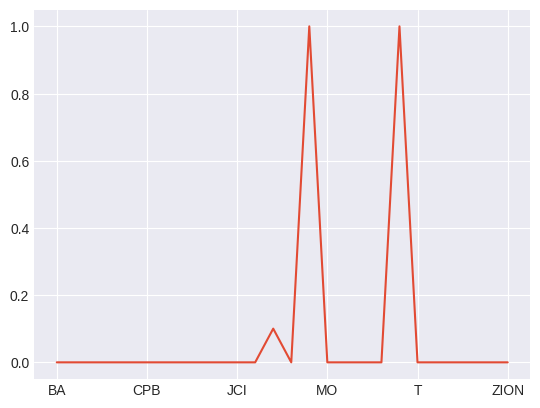

In [59]:
prices.isna().mean().plot()

In [60]:
# Remove stocks with over 20% invalid/missing prices, then incomplete dates.
prices = prices.loc[:, prices.isna().mean() <= 0.20].dropna()

# Daily log returns, computed on the same dates for every portfolio.
returns = np.log(prices / prices.shift(1)).dropna()

In [61]:
# Number of assets
num_act = prices.shape[1]

In [62]:
# Calculate log returns
returns = np.log(prices).diff().dropna()
returns.head(2)

,BA,BAX,BMY,CMCSA,CNP,CPB,DE,F,GE,HPQ,...,MO,NI,PCAR,PSA,T,TGT,TMO,TXT,VZ,ZION
Date,,,,,,,,,,,,,,,,,,,,,
2015-07-07,0.018543,-0.024752,0.010757,0.006419,0.019578,0.014908,0.007402,0.004049,0.006063,0.007496,...,0.035651,0.016490,0.003577,0.022570,0.004483,0.018162,0.004286,-0.003387,0.004454,-0.021061
2015-07-08,-0.008629,-0.016574,-0.007208,-0.013205,-0.019578,-0.008582,-0.013805,-0.032857,-0.022155,-0.011429,...,-0.012657,0.001168,-0.023246,0.003109,-0.010230,-0.011552,-0.021224,-0.028682,-0.002573,-0.026208


In [63]:
# Calculate the covariance matrix and expected returns
matriz_cov = returns.cov().to_numpy()
retornos_esperados = returns.mean().to_numpy()

Let us examine the correlations between assets.

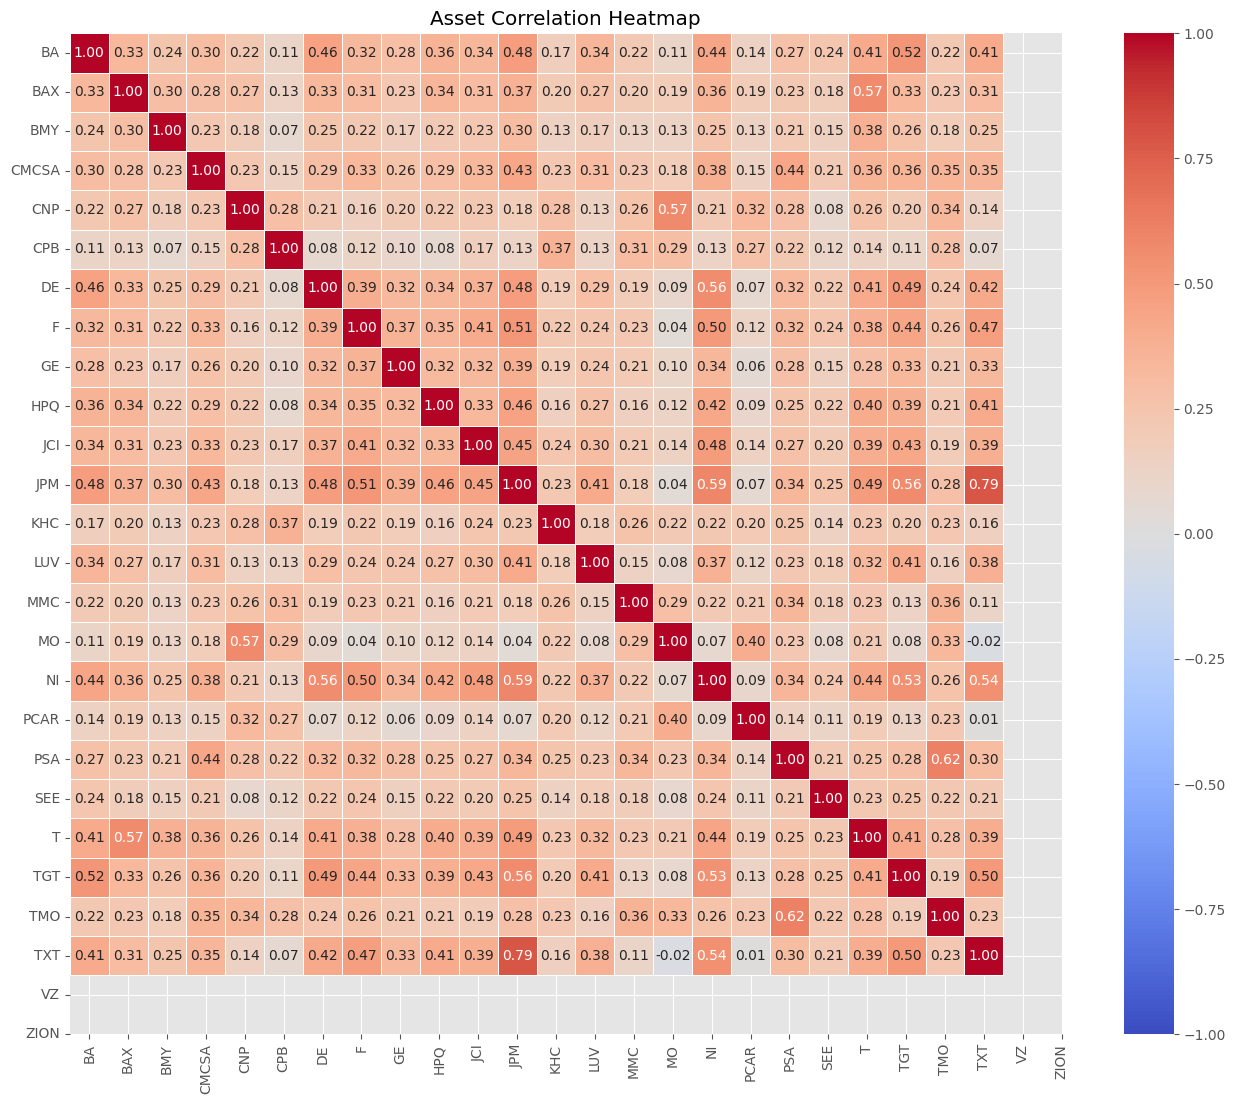

In [50]:
# Correlation matrix
mat_corr = returns.corr().to_numpy()

# Set figure size
plt.figure(figsize=(16, 13))
sns.heatmap(
    mat_corr,
    linewidths=0.5,
    cmap="coolwarm",
    xticklabels=assets,
    yticklabels=assets,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
)
# Add title
plt.title("Asset Correlation Heatmap")

# Display plot
plt.show()

Let us plot the assets in risk-return space.

In [51]:
print("Number of assets:", len(assets))
print("Covariance matrix shape:", matriz_cov.shape)
print("Expected returns:", len(retornos_esperados))

Number of assets: 26
Covariance matrix shape: (24, 24)
Expected returns: 24


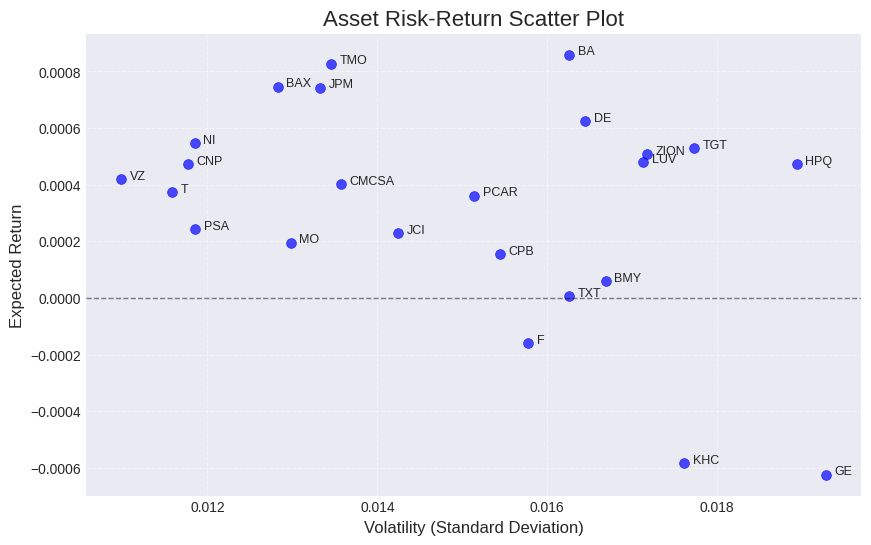

In [52]:
# Set chart size and style
plt.figure(figsize=(10, 6))
plt.style.use("seaborn-v0_8-darkgrid")

plt.scatter(
    np.sqrt(np.diag(matriz_cov)),
    retornos_esperados,
    color="blue",
    s=50,
    label="Assets",
    alpha=0.7,
)

plt.axhline(0, color="black", lw=1, linestyle="--", alpha=0.5)

# Add title and axis labels
plt.title("Asset Risk-Return Scatter Plot", fontsize=16)
plt.xlabel("Volatility (Standard Deviation)", fontsize=12)
plt.ylabel("Expected Return", fontsize=12)

# Place the legend
# plt.legend(loc='best')

# Add asset names with an offset
desplazamiento_x = 0.0001  # Adjust as needed

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )


# Display grid for readability
plt.grid(True, linestyle="--", alpha=0.5)

# Display the plot
plt.show()

## Exercise 3: Finding the *Minimum-Risk Portfolio*

Find the *minimum-risk portfolio* without short selling.

In [64]:
# TODO Decision variables
pesos = cp.Variable(num_act)

In [74]:
# TODO: define constraints
riesgo = cp.QuadForm(pesos,matriz_cov)
retornos = retornos_esperados@ pesos
objetivo = cp.Minimize(riesgo)

In [75]:
# TODO: objective function
constraints = [cp.sum(pesos) == 1, pesos >=0]
problema = cp.Problem(objetivo,constraints)

In [76]:
# TODO Problema y resuelvo
# Solve the problem
resultado = problema.solve()

# Results
pesos_optimos = pesos.value

In [77]:
print(
    f"Los pesos que hacen que la cartera tenga el mayor retorno para un riesgo maximo de 1.2 son: {100*pesos_optimos.round(2)}")

Los pesos que hacen que la cartera tenga el mayor retorno para un riesgo maximo de 1.2 son: [-0.  8.  5.  3.  7.  4.  0.  1.  0. -0.  4.  6. -0.  3.  7. 11. -0. 17.
  8.  5. -0. -0.  9.  1.]


In [78]:
# Check whether an optimal solution was found
if problema.status == cp.OPTIMAL:
    # Results
    pesos_optimos = pesos.value
    print(f"Optimization successful. Optimal value: {resultado}")
else:
    print(f"No optimal solution found. Status: {problema.status}")
    if problema.status == cp.INFEASIBLE:
        print(
            "The problem is infeasible. The constraints cannot all be satisfied."
        )
    elif problema.status == cp.UNBOUNDED:
        print(
            "The problem is unbounded. The objective can improve indefinitely."
        )
    elif problema.status == cp.OPTIMAL_INACCURATE:
        print("An optimal solution was found, but with reduced accuracy.")
        pesos_optimos = pesos.value

Optimization successful. Optimal value: 4.973141664234276e-05


In [79]:
# Save the return and risk of the minimum-risk portfolio
ret = retornos_esperados.T @ pesos
min_riesgo = np.array([riesgo.value, ret.value])

In [80]:
print(f"Weights of the minimum-risk portfolio: \n{pesos.value}")

Weights of the minimum-risk portfolio: 
[-8.47093138e-19  8.41940405e-02  4.50145458e-02  2.72181210e-02
  6.67018524e-02  4.03068753e-02  4.08789258e-03  8.27669645e-03
  4.32859871e-03 -7.30768597e-19  4.30962886e-02  6.28058009e-02
 -3.90184269e-20  3.04337654e-02  7.49980847e-02  1.12570499e-01
 -9.62599867e-20  1.68022282e-01  8.22756328e-02  4.71838128e-02
 -5.62806043e-19 -7.51212192e-19  9.26404237e-02  5.84478656e-03]


Portfolio weights can be visualized in different ways. One option is to use a bar chart showing the weight $w_i$ of each asset.

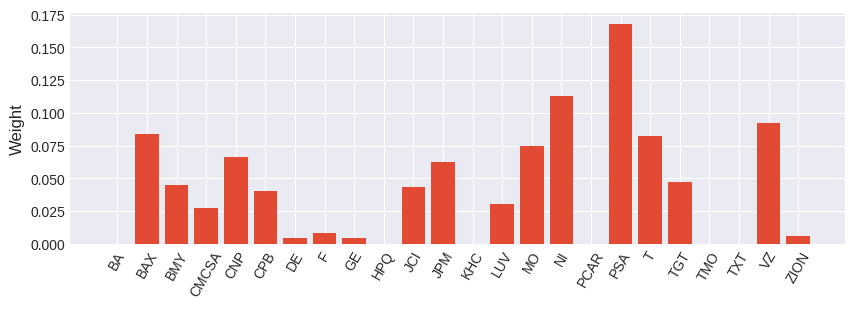

In [82]:
plt.figure(figsize=(10, 3))
plt.bar(range(num_act), pesos.value)
plt.xticks(range(num_act), returns.columns, rotation=60)
plt.ylabel("Weight")
plt.show()

Another option is a pie chart.

CVXPY solves the problem numerically. This can produce extremely small weights: in the previous example, some weights are of order $10^{-9}$, which we can set to zero.

In [83]:
# ponemos a cero los pesos menores a 10**-4

pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])
pesos_ajustados

array([0.   , 0.084, 0.045, 0.027, 0.067, 0.04 , 0.004, 0.008, 0.004,
       0.   , 0.043, 0.063, 0.   , 0.03 , 0.075, 0.113, 0.   , 0.168,
       0.082, 0.047, 0.   , 0.   , 0.093, 0.006])

In [85]:
activos_filtrados = [
    asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0
]  # Activos con pesos mayores a 10**-4


pesos_filtrados = [x for x in pesos_ajustados if x > 0]  # Pesos mayores a 10**-4

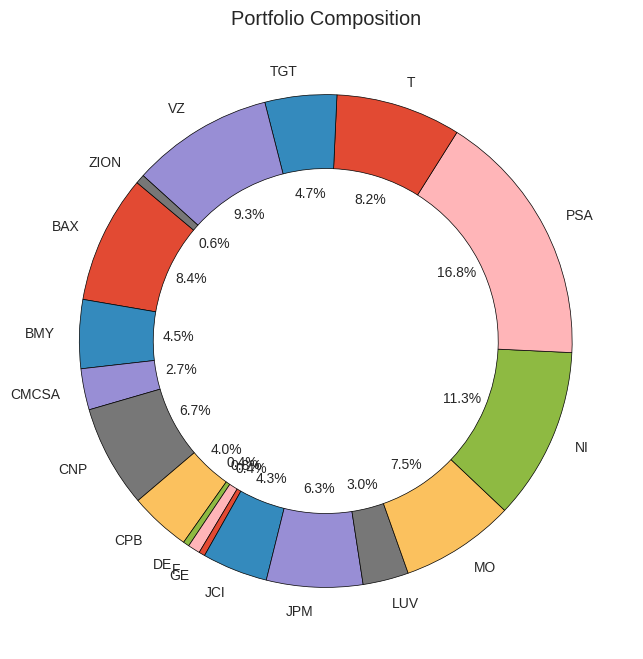

In [86]:
# Create donut chart
plt.figure(figsize=(8, 8))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Portfolio Composition")

# Display the plot
plt.show()

## Exercise 4: Finding the *Maximum-Return Portfolio*

Now find the portfolio with the highest expected return, assuming short selling is not allowed.

In [87]:
# Decision variables
pesos = cp.Variable(num_act)

In [88]:
# Constraints
constraints = [
    pesos >= 0,  # No shorting
    cp.sum(pesos) == 1,  # Fully invested
]

In [89]:
# Calculate the maximum-return portfolio

ret = retornos_esperados.T @ pesos

objective = cp.Maximize(ret)

prob = cp.Problem(objective, constraints)
resultado = prob.solve()  # solver=cp.ECOS

In [90]:
# Save the return and risk of the maximum-return portfolio
riesgo = cp.quad_form(pesos, matriz_cov)
max_ret = np.array([riesgo.value, ret.value])

Let us visualize the weights again, using both a bar chart and a pie chart.

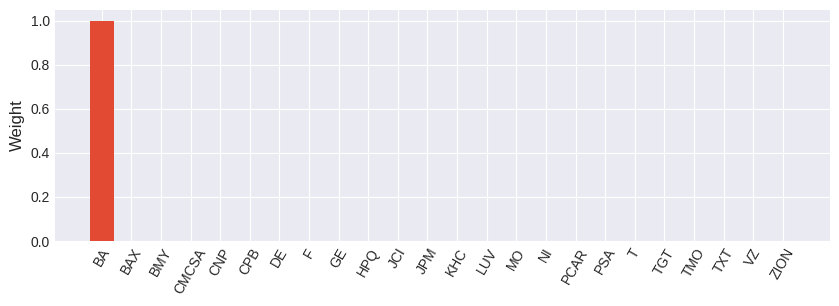

In [91]:
plt.figure(figsize=(10, 3))
plt.bar(range(num_act), pesos.value)
plt.xticks(range(num_act), returns.columns, rotation=60)
plt.ylabel("Weight")
plt.show()

In [92]:
pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

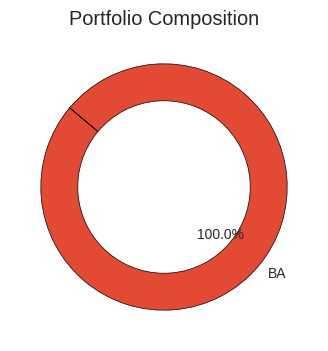

In [93]:
# Create donut chart
plt.figure(figsize=(4, 4))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Portfolio Composition")

# Display the plot
plt.show()

Now let us plot these portfolios together with the individual assets.

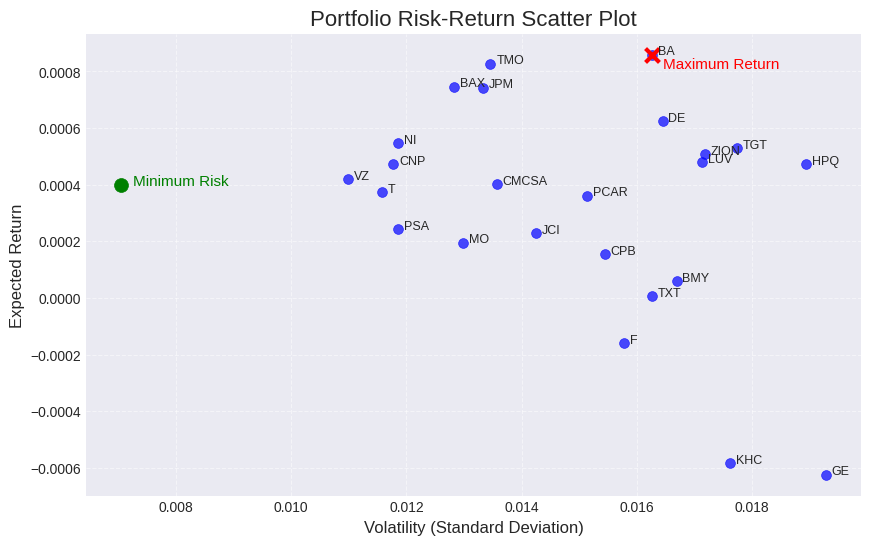

In [94]:
# Set chart size and style
plt.figure(figsize=(10, 6))

# Points for each asset
plt.scatter(
    np.sqrt(np.diag(matriz_cov)),  # Volatilidad
    retornos_esperados,  # Retorno
    color="blue",
    s=50,
    label="Assets",
    alpha=0.7,
)

# Add asset names with an offset
desplazamiento_x = 0.0001  # Adjust as needed
desplazamiento_y = 0.00005  # Adjust as needed

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )


# Minimum-risk portfolio point
plt.scatter(
    np.sqrt(min_riesgo[0]),
    min_riesgo[1],
    color="green",
    s=100,
    marker="o",
    label="Minimum Risk",
)
plt.text(
    np.sqrt(min_riesgo[0]) + 2 * desplazamiento_x,
    min_riesgo[1],
    "Minimum Risk",
    fontsize=11,
    color="green",
)

# Maximum-return portfolio point
plt.scatter(
    np.sqrt(max_ret[0]),
    max_ret[1],
    color="red",
    s=100,
    marker="x",
    linewidths=3,
    label="Maximum Return",
)
plt.text(
    np.sqrt(max_ret[0]) + 2 * desplazamiento_x,
    max_ret[1] - desplazamiento_y,
    "Maximum Return",
    fontsize=11,
    color="red",
)

# Add title and axis labels
plt.title("Portfolio Risk-Return Scatter Plot", fontsize=16)
plt.xlabel("Volatility (Standard Deviation)", fontsize=12)
plt.ylabel("Expected Return", fontsize=12)

# Place the legend
# plt.legend(loc='best')

# Display grid for readability
plt.grid(True, linestyle="--", alpha=0.5)

# Display the plot
plt.show()

## Exercise 5: *Maximum-Return Portfolio* Subject to a *Maximum Risk Limit*

Find the portfolio with the highest expected return without exceeding the specified maximum risk of `0.012`.

In [96]:
# maximum risk
riesgo_obj = 0.012

In [103]:
# TODO Decision variables
pesos = cp.Variable(num_act)

# TODO: define the objective function
ret = retornos_esperados.T @ pesos

riesgo = cp.quad_form(pesos, matriz_cov)

objetivo = cp.Maximize(ret)

# TODO: define constraints
constraints = [pesos >= 0, cp.sum(pesos) == 1, riesgo <= riesgo_obj**2]

problema = cp.Problem(objetivo, constraints)

# TODO Problema y resuelvo
resultado = problema.solve()


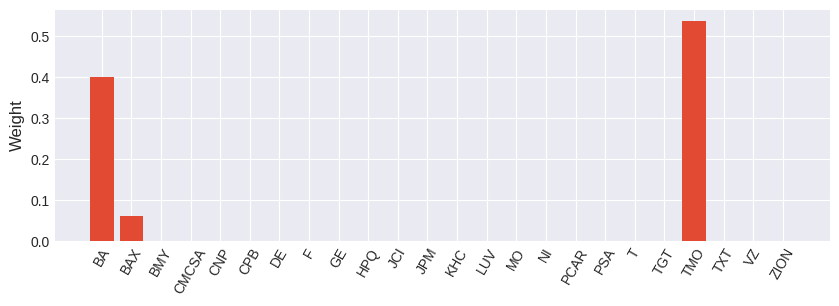

In [104]:
plt.figure(figsize=(10, 3))
plt.bar(range(num_act), pesos.value)
plt.xticks(range(num_act), returns.columns, rotation=60)
plt.ylabel("Weight")
plt.show()

In [105]:
# Check whether an optimal solution was found
if problema.status == cp.OPTIMAL:
    # Results
    pesos_optimos = pesos.value
    print(f"Optimization successful. Optimal value: {resultado}")
else:
    print(f"No optimal solution found. Status: {problema.status}")
    if problema.status == cp.INFEASIBLE:
        print(
            "The problem is infeasible. The constraints cannot all be satisfied."
        )
    elif problema.status == cp.UNBOUNDED:
        print(
            "The problem is unbounded. The objective can improve indefinitely."
        )
    elif problema.status == cp.OPTIMAL_INACCURATE:
        print("An optimal solution was found, but with reduced accuracy.")
        pesos_optimos = pesos.value

Optimization successful. Optimal value: 0.0008348088349662773


In [108]:
pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

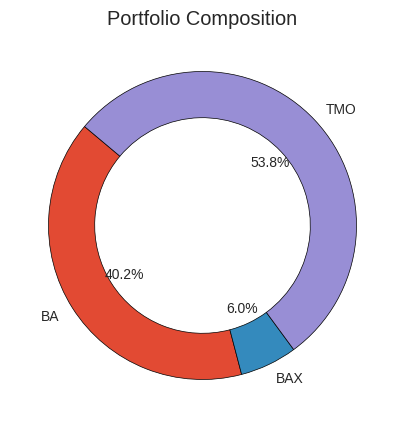

In [109]:
# Create donut chart
plt.figure(figsize=(5, 5))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Portfolio Composition")

# Display the plot
plt.show()

Let us plot the portfolio alongside the individual assets.

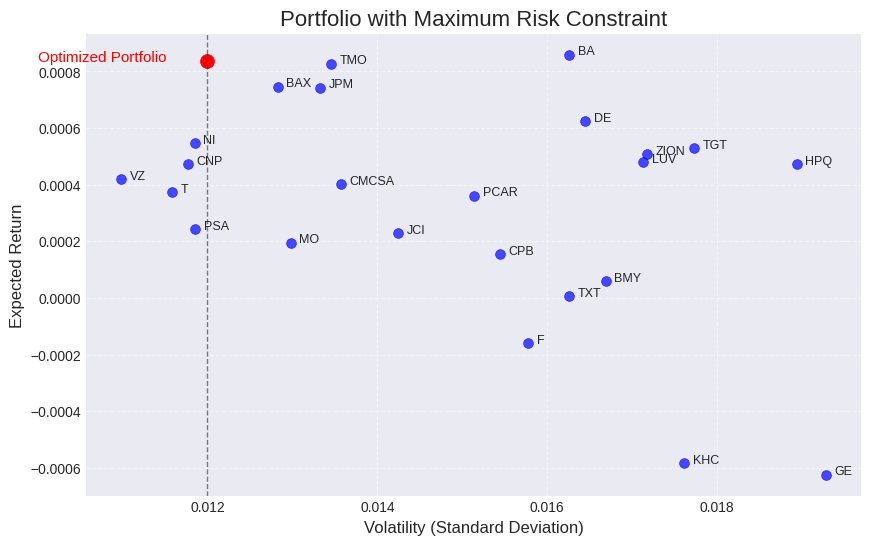

In [110]:
# Set chart size and style
plt.figure(figsize=(10, 6))

# Points for each asset
plt.scatter(
    np.sqrt(np.diag(matriz_cov)), retornos_esperados, color="blue", s=50, alpha=0.7
)


# Add asset names with an offset
desplazamiento_x = 0.0001  # Adjust as needed
desplazamiento_y = 0.00003  # Adjust as needed

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )


plt.scatter(np.sqrt(riesgo.value), resultado, color="red", s=100, marker="o")
plt.text(
    np.sqrt(riesgo.value) - 20 * desplazamiento_x,
    resultado,
    "Optimized Portfolio",
    fontsize=11,
    color="red",
)

plt.axvline(riesgo_obj, color="black", lw=1, linestyle="--", alpha=0.5)


# Add title and axis labels
plt.title("Portfolio with Maximum Risk Constraint", fontsize=16)
plt.xlabel("Volatility (Standard Deviation)", fontsize=12)
plt.ylabel("Expected Return", fontsize=12)

# Place the legend
# plt.legend(loc='best')

# Display grid for readability
plt.grid(True, linestyle="--", alpha=0.5)

# Display the plot
plt.show()

## Exercise 6: *Maximum-Return Portfolios for Different Levels of Risk Aversion*

Investors differ in their willingness to take risk, often described through risk aversion. Recall the Markowitz objective:

$$\underset{w}{\max} f(w)=w^T\mu-\lambda w^T\Sigma w$$

We will now find maximum-return portfolios for different levels of risk aversion.

- The parameter $\Large \boldsymbol{\lambda}$ represents an investor's risk aversion.
- It must satisfy $\Large \boldsymbol{\lambda} \geq 0$.
- A low $\Large \boldsymbol{\lambda}$ indicates greater willingness to take risks in search of higher returns.
- A high $\Large \boldsymbol{\lambda}$ indicates a preference for safer investments, even at the cost of lower expected returns.
- $\Large \boldsymbol{\lambda}$ balances risk and return in portfolio selection.

Note: This example is based on the [CVXPY documentation](https://www.cvxpy.org/).

In [111]:
# Decision variables
pesos = cp.Variable(num_act)

# Risk-aversion parameter
gamma = cp.Parameter(
    nonneg=True
)  # No lo llamo lambda porque es una palabra reservada en python

ret = retornos_esperados.T @ pesos

riesgo = cp.quad_form(pesos, matriz_cov)

We define the **objective function**:

- The objective is to maximize returns while penalizing risk.
- Subtracting risk multiplied by the parameter gamma means that, for the same expected return, the optimization favors less risky portfolios.
- A high gamma indicates strong risk aversion: safety is prioritized even if expected returns are lower.

In [112]:
objetivo = cp.Maximize(ret - gamma * riesgo)

In [113]:
# Constraints and objective function
constraints = [pesos >= 0, cp.sum(pesos) == 1]

prob = cp.Problem(objetivo, constraints)

In [114]:
# Solve for different gamma values
num_sim = 100
riesgos_res = np.zeros(num_sim)
retornos_res = np.zeros(num_sim)
pesos_res = np.zeros((num_sim, num_act))
gamma_vals = np.logspace(-2, 3, num=num_sim)

for i in range(num_sim):
    gamma.value = gamma_vals[i]
    prob.solve()
    retornos_res[i] = ret.value
    riesgos_res[i] = cp.sqrt(riesgo).value
    pesos_res[i, :] = pesos.value

In [115]:
pesos_res.shape

(100, 24)

Now let us plot all the results.

<>:46: SyntaxWarning: invalid escape sequence '\g'
<>:51: SyntaxWarning: invalid escape sequence '\g'
<>:65: SyntaxWarning: invalid escape sequence '\g'
<>:70: SyntaxWarning: invalid escape sequence '\g'
<>:84: SyntaxWarning: invalid escape sequence '\g'
<>:89: SyntaxWarning: invalid escape sequence '\g'
<>:46: SyntaxWarning: invalid escape sequence '\g'
<>:51: SyntaxWarning: invalid escape sequence '\g'
<>:65: SyntaxWarning: invalid escape sequence '\g'
<>:70: SyntaxWarning: invalid escape sequence '\g'
<>:84: SyntaxWarning: invalid escape sequence '\g'
<>:89: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_2375/3997350182.py:46: SyntaxWarning: invalid escape sequence '\g'
  label=f"$\gamma$ = {gamma_vals[num_sim-1]:.2f}",
/tmp/ipykernel_2375/3997350182.py:51: SyntaxWarning: invalid escape sequence '\g'
  f"$\gamma$ = {gamma_vals[num_sim-1]:.2f} \n Baja tolerancia al  riesgo",
/tmp/ipykernel_2375/3997350182.py:65: SyntaxWarning: invalid escape sequence '\g'
  label=f"$\gamm

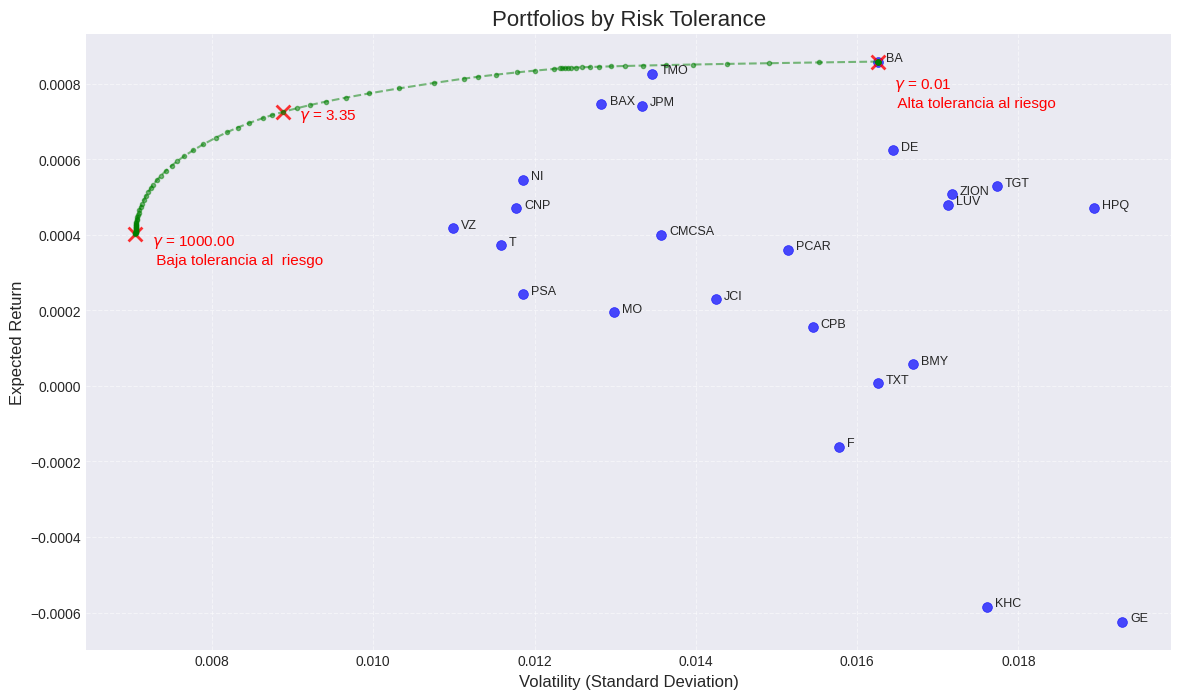

In [119]:
# Set chart size and style
plt.figure(figsize=(14, 8))
plt.style.use("seaborn-v0_8-darkgrid")

# Points for each asset
plt.scatter(
    np.sqrt(np.diag(matriz_cov)),
    retornos_esperados,
    color="blue",
    s=50,
    label="Assets",
    alpha=0.7,
)

# Add asset names with an offset
desplazamiento_x = 0.0001  # Adjust as needed
desplazamiento_y = 0.00002  # Adjust as needed

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )

# Portfolios along the efficient frontier.
plt.plot(
    riesgos_res,
    retornos_res,
    ".--",
    color="green",
    label="Efficient Frontier",
    alpha=0.5,
)

# Last portfolio on the efficient frontier.
plt.scatter(
    riesgos_res[num_sim - 1],
    retornos_res[num_sim - 1],
    color="red",
    s=100,
    marker="x",
    linewidths=2,
    alpha=0.8,
    label=f"$\gamma$ = {gamma_vals[num_sim-1]:.2f}",
)
plt.text(
    riesgos_res[num_sim - 1] + 2 * desplazamiento_x,
    retornos_res[num_sim - 1] - 4 * desplazamiento_y,
    f"$\gamma$ = {gamma_vals[num_sim-1]:.2f} \n Baja tolerancia al  riesgo",
    fontsize=11,
    color="red",
)

# Cartera intermedia en la frontera eficiente.
plt.scatter(
    riesgos_res[int(num_sim / 2)],
    retornos_res[int(num_sim / 2)],
    color="red",
    s=100,
    marker="x",
    linewidths=2,
    alpha=0.8,
    label=f"$\gamma$ = {gamma_vals[int(num_sim/2)]:.2f}",
)
plt.text(
    riesgos_res[int(num_sim / 2)] + 2 * desplazamiento_x,
    retornos_res[int(num_sim / 2)] - desplazamiento_y,
    f"$\gamma$ = {gamma_vals[int(num_sim/2)]:.2f}",
    fontsize=11,
    color="red",
)

# Primera cartera en la frontera eficiente.
plt.scatter(
    riesgos_res[int(0)],
    retornos_res[int(0)],
    color="red",
    s=100,
    marker="x",
    linewidths=2,
    alpha=0.8,
    label=f"$\gamma$ = {gamma_vals[int(0)]:.2f}",
)
plt.text(
    riesgos_res[int(0)] + 2 * desplazamiento_x,
    retornos_res[int(0)] - 6 * desplazamiento_y,
    f"$\gamma$ = {gamma_vals[0]:.2f}\n Alta tolerancia al riesgo",
    fontsize=11,
    color="red",
)

# Add title and axis labels
plt.title("Portfolios by Risk Tolerance", fontsize=16)
plt.xlabel("Volatility (Standard Deviation)", fontsize=12)
plt.ylabel("Expected Return", fontsize=12)

# Place the legend
# plt.legend(loc="best")

# Display grid for readability
plt.grid(True, linestyle="--", alpha=0.5)

# Display the plot
plt.show()

<>:30: SyntaxWarning: invalid escape sequence '\g'
<>:30: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_2375/4084249384.py:30: SyntaxWarning: invalid escape sequence '\g'
  plt.xlabel("Risk Aversion $\gamma$")
/tmp/ipykernel_2375/4084249384.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  paleta = cm.get_cmap("tab20c", num_act)


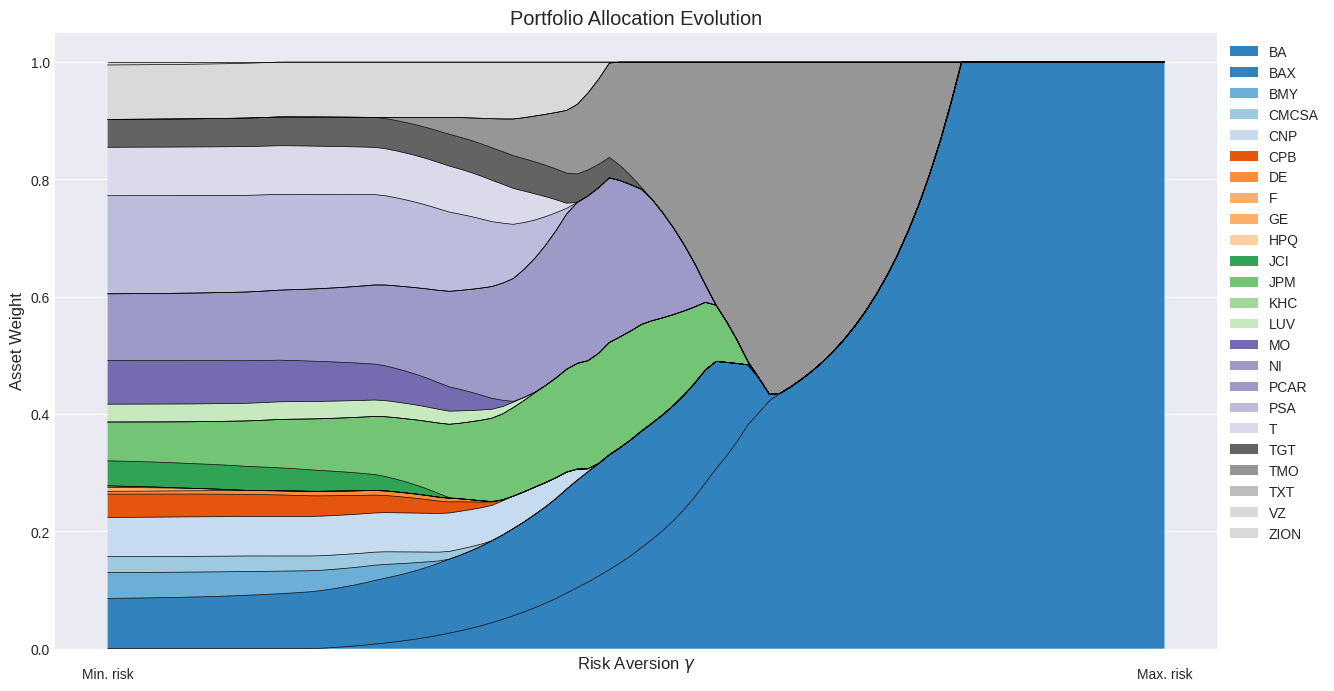

In [120]:
# Choose a color palette and generate colors
from matplotlib import cm

paleta = cm.get_cmap("tab20c", num_act)
colores = [paleta(i) for i in range(num_act)]

# Create a stacked area chart
tiempo = np.arange(num_sim)  # X-axis: time

plt.figure(figsize=(15, 8))

plt.stackplot(
    tiempo, pesos_res.T, colors=colores, labels=[f"{returns.columns[i]}" for i in range(num_act)]
)

# Add borders to the areas
for i in range(num_act):
    plt.plot(
        tiempo, np.sum(pesos_res[:, : i + 1], axis=1), color="black", linewidth=0.5
    )

# Invert the x-axis
plt.gca().invert_xaxis()

# Add custom labels to the x-axis
plt.text(num_sim - 1, -0.05, "Min. risk", ha="center")  # Near 100
plt.text(0, -0.05, "Max. risk", ha="center")  # Near 0


plt.xlabel("Risk Aversion $\gamma$")
plt.ylabel("Asset Weight")
plt.title("Portfolio Allocation Evolution")

# Place legend outside the chart
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.xticks([], [])

plt.show()

## Exercise 7: Portfolios with a Maximum Allocation per Asset

Find the portfolio with the highest possible expected return while ensuring that no individual asset receives more than a specified percentage of total investment.

In [121]:
# Decision variables
pesos = cp.Variable(num_act)

# Objective function
rentabilidad = cp.Maximize(retornos_esperados.T @ pesos)

In [127]:
# TODO: define constraints
constraints = [pesos >= 0, cp.sum(pesos) == 1, pesos <= 0.2]
problem = cp.Problem(rentabilidad, constraints)

resuelto = problem.solve()
pesos.value

array([1.99999795e-01, 1.99999604e-01, 4.00129590e-08, 9.18577978e-08,
       1.79572948e-07, 4.61367528e-08, 1.99998759e-01, 3.09042852e-08,
       2.10187009e-08, 1.78943665e-07, 5.26522498e-08, 1.99999167e-01,
       2.15994107e-08, 2.04738115e-07, 4.93651187e-08, 8.31874780e-07,
       7.53720542e-08, 5.40965267e-08, 7.94431595e-08, 5.24940951e-07,
       1.99999720e-01, 3.73935839e-08, 1.03715385e-07, 3.30610639e-07])

In [130]:
pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

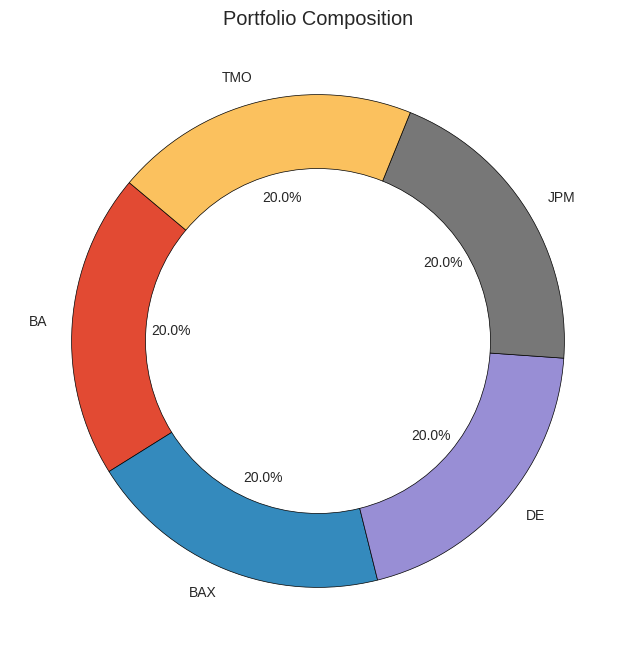

In [131]:
# Create donut chart
plt.figure(figsize=(8, 8))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Portfolio Composition")

# Display the plot
plt.show()

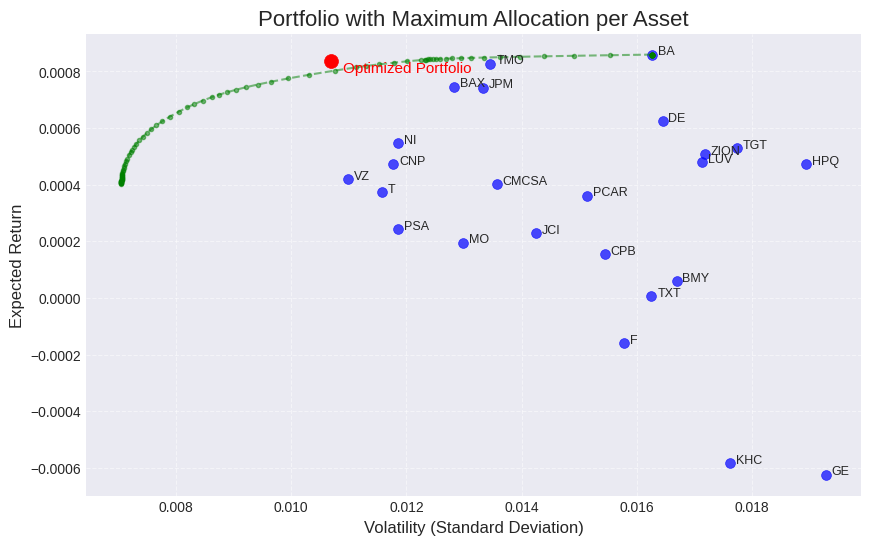

In [133]:
# Set chart size and style
plt.figure(figsize=(10, 6))

# Points for each asset
plt.scatter(
    np.sqrt(np.diag(matriz_cov)),
    retornos_esperados,
    color="blue",
    s=50,
    label="Assets",
    alpha=0.7,
)

# Add asset names with an offset
desplazamiento_x = 0.0001  # Adjust as needed
desplazamiento_y = 0.00002  # Adjust as needed

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )

# Portfolios along the efficient frontier.
plt.plot(
    riesgos_res,
    retornos_res,
    ".--",
    color="green",
    label="Efficient Frontier",
    alpha=0.5,
)

# Optimized portfolio.
plt.scatter(
    np.sqrt(cp.quad_form(pesos, matriz_cov).value),
    resultado,
    color="red",
    s=100,
    marker="o",
    label="Optimized Portfolio",
)
plt.text(
    np.sqrt(cp.quad_form(pesos, matriz_cov).value) + 2 * desplazamiento_x,
    resultado - 2 * desplazamiento_y,
    "Optimized Portfolio",
    fontsize=11,
    color="red",
)

# Add title and axis labels
plt.title("Portfolio with Maximum Allocation per Asset", fontsize=16)
plt.xlabel("Volatility (Standard Deviation)", fontsize=12)
plt.ylabel("Expected Return", fontsize=12)

# Place the legend
# plt.legend(loc='best')

# Display grid for readability
plt.grid(True, linestyle="--", alpha=0.5)

# Display the plot
plt.show()

## Exercise 8: Portfolios with a Minimum Number of Assets, a Minimum Investment per Asset, and an Expected-Return Constraint

Find a portfolio that not only exceeds a required return level but also holds at least a specified number of assets, thereby encouraging diversification.

In [134]:
pesos = cp.Variable(num_act)
riesgo = cp.quad_form(pesos, matriz_cov)
factor = 0.8
minimum_return = factor * retornos_esperados.max()
ret = retornos_esperados.T @ pesos

constraints = [cp.sum(pesos) == 1, pesos >= 0, ret >= minimum_return]

We now define constraints that ensure a minimum number of assets in the portfolio:

* Set `min_act = 12` to require at least 12 assets in the portfolio.

* Set `peso_minimo = 0.05` to specify the minimum percentage invested in any selected asset.

In [135]:
min_act = 12  # Minimum number of assets in the portfolio
peso_minimo = 0.05  # Minimum percentage invested in any selected asset

**Including at least `min_act` assets**:

- Binary selection variables (`selection`) are used. Each variable equals 1 if the asset is included in the portfolio and 0 otherwise.
- `cp.sum(selection) >= min_act` ensures that at least `min_act` assets are included.

In [136]:
selection = cp.Variable(num_act, boolean=True)
constraints.append(cp.sum(selection) >= min_act)

**Linking selection variables to portfolio weights**:

- `pesos <= selection` links each weight to its selection variable.
- `pesos >= peso_minimo * selection` sets the minimum weight for a selected asset.

    - If an asset is not selected (`selection[i] = 0`), its weight (`pesos[i]`) must equal zero. The asset therefore makes no contribution to the portfolio.
    - If an asset is selected (`selection[i] = 1`), its weight can be positive, so the asset can enter the portfolio.
    - The second constraint ensures that the weight of any selected asset is at least `peso_minimo`.

These constraints ensure that only selected assets contribute to the portfolio.

In [137]:
constraints.append(pesos <= selection)
constraints.append(pesos >= peso_minimo * selection)

In [138]:
problem = cp.Problem(cp.Minimize(riesgo), constraints)

resultado = problem.solve(
    solver=cp.ECOS_BB
)  # Specify the solver because the model contains binary variables

SolverError: The solver ECOS_BB is not installed.

TypeError: unsupported operand type(s) for +: 'int' and 'NoneType'

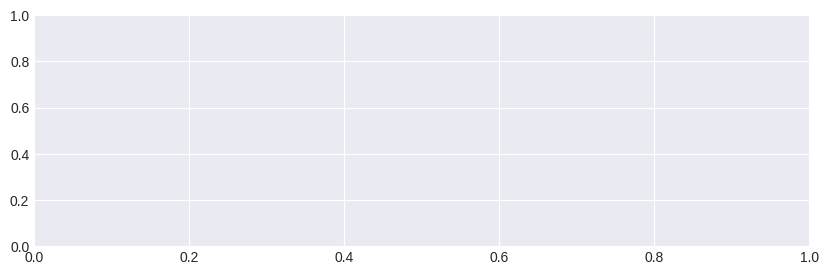

In [139]:
plt.figure(figsize=(10, 3))
plt.bar(range(num_act), pesos.value)
plt.xticks(range(num_act), assets, rotation=60)
plt.ylabel("Weight")
plt.show()

In [ ]:
pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

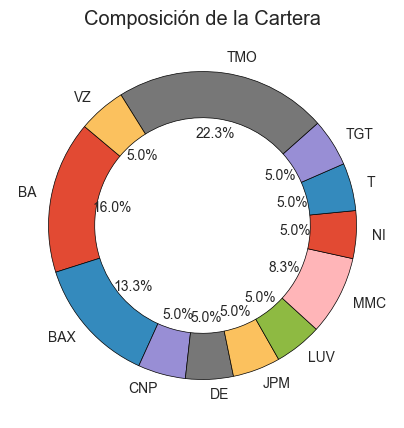

In [ ]:
# Create donut chart
plt.figure(figsize=(5, 5))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Portfolio Composition")

# Display the plot
plt.show()

In [ ]:
# Calculate portfolio return
ret = (retornos_esperados.T @ pesos).value

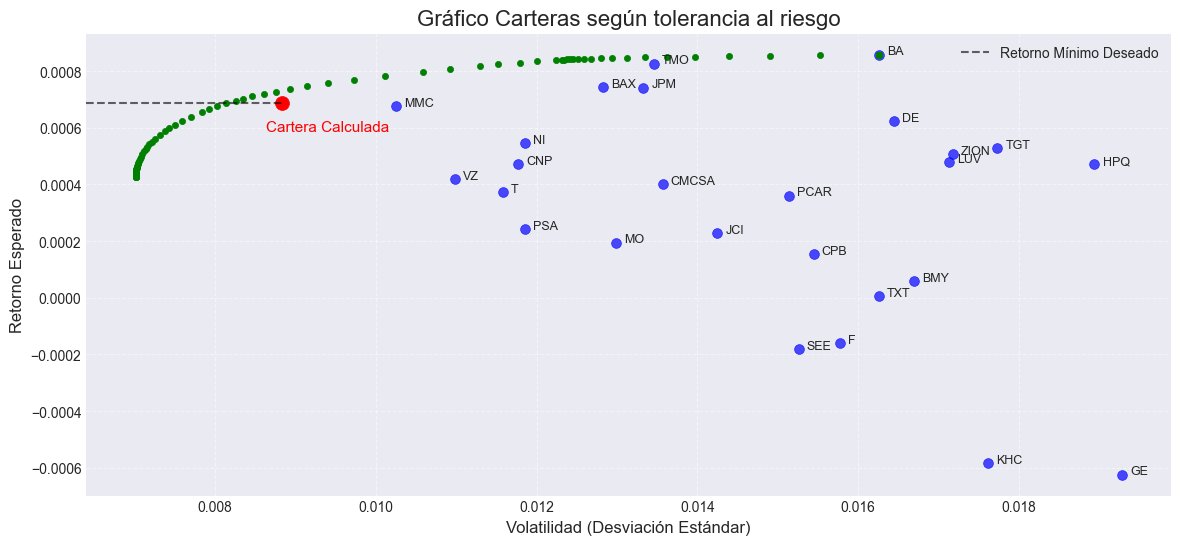

In [ ]:
# Set chart size and style
plt.figure(figsize=(14, 6))

# Points for each asset
plt.scatter(
    np.sqrt(np.diag(matriz_cov)), retornos_esperados, color="blue", s=50, alpha=0.7
)

# Add asset names with an offset
desplazamiento_x = 0.0001  # Adjust as needed
desplazamiento_y = 0.0001  # Adjust as needed

for i, asset in enumerate(assets):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )

# plt.scatter(riesgos_res, retornos_res, color='green', s=20, marker='o')#,  alpha=0.3)

plt.axhline(
    xmin=0,
    xmax=0.18,
    y=minimum_return,
    color="black",
    linestyle="--",
    label="Required Minimum Return",
    alpha=0.6,
)


plt.scatter(np.sqrt(resultado), ret, color="red", s=100, marker="o")
plt.text(
    np.sqrt(resultado) - 2 * desplazamiento_x,
    ret - desplazamiento_y,
    "Optimized Portfolio",
    fontsize=11,
    color="red",
)

plt.scatter(riesgos_res, retornos_res, color="green", s=20, marker="o")

# Add title and axis labels
plt.title("Portfolios by Risk Tolerance", fontsize=16)
plt.xlabel("Volatility (Standard Deviation)", fontsize=12)
plt.ylabel("Expected Return", fontsize=12)

# Place the legend
plt.legend(loc="best")

# Display grid for readability
plt.grid(True, linestyle="--", alpha=0.5)

# Display the plot
plt.show()